In [1]:
%reset -f

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch

from pathlib import Path
from datetime import datetime

import sys
sys.path.append("../../tools")
import evaluation as eva
import prepare as prep
import functions as func

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [2]:
import importlib
#importlib.reload(eva)
#importlib.reload(prep)
#importlib.reload(func)


In [ ]:
rep = 1 #rep1, AUPRC=0.88(fluctuation_15fold_v2)

load_dir1 = Path(f"../../saved_models/fluctuation_15fold_v2/sp3to20_Fl_transpt3_r{rep}")
#load_dir1 = Path(f"../../saved_models/fluctuation/sp3to20_Fl_transpt_AUPRC51")
#load_dir1 = Path(f"../../saved_models/fluctuation_3fold_v0/sp3to20_Fl_transpt3_r{rep}")

fmodel = func.load_saved_model_MD(load_dir1, device)
fevaluator = func.TrteEvaluator(fmodel)

split_df = pd.read_csv(f"split_fl_v2/split_fl_{rep}.csv")
folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20_fl"
narray_te = prep.load_split_dataset(
    split_df,
    folder_path,
    #richness_list=[20],
    richness_list=list(range(3,21)),
    subset="te",
    sample_size=3000
)

# split_df = pd.read_csv(f"split_MD_v1/split_MD_{rep}.csv")
# folder_path = "../../Databases/Ver1.9/ver1.9.6_upto20"
# narray_te = prep.load_split_dataset(
#     split_df,
#     folder_path,
#     #richness_list=[20],
#     richness_list=list(range(3,21)),
#     subset="te",
#     sample_size=3000
# )

# overlap_te = 'Ver1.9/ver1.9.6_upto20_te/20-20_102400'
# df_te = pd.read_csv(f'../../Databases/{overlap_te}.csv')
# narray_te = df_te.iloc[:, :-2].values

# overlap_te = 'Ver1.9/ver1.9.6/10-20_102400'
# df_te = pd.read_csv(f'../../Databases/{overlap_te}.csv')
# narray_te = df_te.iloc[:, :-2].values


c:\Users\HW\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


te shape = (3000, 465)


In [4]:
# Evaluate the model on the test set
y_te, y_prob = fevaluator.predict_array_Fl(narray_te, device, sample_size=3000)

#threshold=0.8
threshold=0.45
#threshold=0.6


y_pred = (y_prob >= threshold).astype(int)

metrics = eva.eval_binary(y_te, y_prob, threshold=threshold)
df_metrics = pd.DataFrame([metrics])
display(df_metrics)


,Accuracy,Balanced_Acc,F1,MCC,AUC,AUPRC,AUPRC_rel,Brier,pos_rate
0,0.825333,0.824122,0.801063,0.645786,0.912367,0.876445,1.031944,0.117305,0.431333


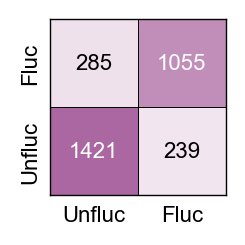

In [5]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

def ConfusionMatrix(species_idx, y_te, y_pr, pdfname=None, normalize=False):

    plt.rcParams.update({
        'font.family': 'Arial',
        'font.size': 8,
        'axes.labelsize': 8, # axis label (text)
        'axes.titlesize': 9,
        'axes.linewidth': 0.5, # axis border line width
        'legend.fontsize': 7, # legend (legend content, not legend title)
        'xtick.major.width': 0.5, # tick line width
        'ytick.major.width': 0.5,
        'xtick.major.size': 1.5, # tick line length (1.5 is relatively short)
        'ytick.major.size': 1.5,
        'xtick.labelsize': 8, # x-axis tick label (numbers)
        'ytick.labelsize': 8,
        'mathtext.fontset': 'stix', # make math formulas more consistent with Arial

        'pdf.fonttype': 42, # preserve Arial font when exporting to PDF
        'ps.fonttype': 42
    })

    y_te = np.asarray(y_te)
    y_pr = np.asarray(y_pr)

    # auto-compatibility
    if y_te.ndim == 2 and y_te.shape[1] > 1:
        y_true = y_te[:, species_idx]
    else:
        y_true = y_te.ravel()

    if y_pr.ndim == 2 and y_pr.shape[1] > 1:
        y_pred = y_pr[:, species_idx]
    else:
        y_pred = y_pr.ravel()

    labels = [0, 1]

    cm = confusion_matrix(
        y_pred,
        y_true,
        labels=labels
    )

    # column normalization
    if normalize:
        cm_plot = cm.astype(float) / cm.sum(axis=0, keepdims=True)
        cm_plot = np.nan_to_num(cm_plot)
        fmt = ".2f"
        vmax = 1
    else:
        cm_plot = cm
        fmt = "d"
        vmax = np.max(cm)

    cm_plot = cm_plot[::-1, :] # flip the y-axis

    #colors = ["#F7845600", "#F92702DB"]
    #colors = ["#ff993f00", "#e8d0ae"]
    colors = ["#ffffff", "#aa67a1"]

    my_cmap = LinearSegmentedColormap.from_list('my_cmap', colors)

    plt.figure(figsize=(1.1, 1.1), dpi=200)

    ax = sns.heatmap(
        cm_plot,
        annot=True,
        fmt=fmt,
        cmap=my_cmap,
        vmin=0,
        vmax=vmax,
        square=True,
        cbar=False,
        linewidths=0.3,
        linecolor='black'
    )

    class_labels = ['Unfluc', 'Fluc']

    ax.set_xticks([0.5, 1.5])
    ax.set_yticks([0.5, 1.5])

    ax.set_xticklabels(class_labels)
    ax.set_yticklabels(class_labels[::-1])

    ax.tick_params(axis='both', which='both', length=0)

    # adaptive text color
    threshold = 0.5 if normalize else vmax * 0.5

    for idx, text in enumerate(ax.texts):

        row = idx // cm_plot.shape[1]
        col = idx % cm_plot.shape[1]

        value = cm_plot[row, col]

        text.set_color('white' if value > threshold else 'black')

    # border
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")

    plt.subplots_adjust(
        left=0.18,
        right=0.98,
        bottom=0.18,
        top=0.98
    )
    if pdfname is not None:

        plt.savefig(
            pdfname,
            dpi=1000,
            bbox_inches="tight",
            transparent=True
        )

    plt.show()

ConfusionMatrix(0, y_te, y_pred, normalize=False,
                #pdfname=f"Con_Fl_v3_{datetime.now().strftime('%Y%m%d_%H%M%S')}.pdf"
)